# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Juan Carlos Gallegos Gutiérrez  
**Grupo:** ISSC 512  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Ruta relativa a la carpeta notebooks/
ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta, index_col=0)  # la primera columna es el índice guardado

print("Primeras cinco filas:")
display(df.head())

print("Dimensiones:", df.shape)
print("\nColumnas:", list(df.columns))
print("\nTipos de datos:")
print(df.dtypes)

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones: (2427612, 20)

Columnas: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type                 str
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_con

In [10]:
# Resumen estadístico de las columnas numéricas
display(df.describe().round(2))

# Valores existentes en payment_type
print(df["payment_type"].value_counts(dropna=False))

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [11]:
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)

print("\nValores nulos por columna (antes):")
print(df_limpio.isnull().sum())
print("\nRegistros duplicados (antes):", df_limpio.duplicated().sum())

# Eliminar duplicados y filas con nulos
df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()
print("\nDimensiones tras quitar duplicados y nulos:", df_limpio.shape)

# Condiciones de validez
condiciones = (
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
)
df_limpio = df_limpio[condiciones]

print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros restantes:", len(df_limpio))
print("Nulos restantes:", df_limpio.isnull().sum().sum(),
      "| Duplicados restantes:", df_limpio.duplicated().sum())

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna (antes):
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Registros duplicados (antes): 11961

Dimensiones tras quitar duplicados y nulos: (2196158, 20)

Dimensiones después de limpiar: (2096600, 20)
Registros restantes: 2096600
Nulos restantes: 0 | Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [12]:
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()
X = df_cash[["trip_distance", "trip_duration"]]

print("Cantidad de viajes pagados en efectivo:", len(df_cash))
display(X.describe().round(2))

Cantidad de viajes pagados en efectivo: 282085


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [13]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = pd.DataFrame(scaler.fit_transform(X_log),
                          columns=X.columns, index=X.index)

print("Variables transformadas con log1p:")
display(X_log.describe().round(3))
print("Variables transformadas y estandarizadas (media ≈ 0, desv. estándar ≈ 1):")
display(X_escalado.describe().round(3))

Variables transformadas con log1p:


,trip_distance,trip_duration
count,282085.000,282085.000
mean,1.225,2.608
std,0.763,0.744
min,0.010,0.033
25%,0.652,2.128
50%,0.993,2.596
75%,1.681,3.086
max,7.431,9.033


Variables transformadas y estandarizadas (media ≈ 0, desv. estándar ≈ 1):


,trip_distance,trip_duration
count,282085.000,282085.000
mean,0.000,-0.000
std,1.000,1.000
min,-1.592,-3.459
25%,-0.751,-0.644
50%,-0.304,-0.015
75%,0.597,0.642
max,8.130,8.631


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


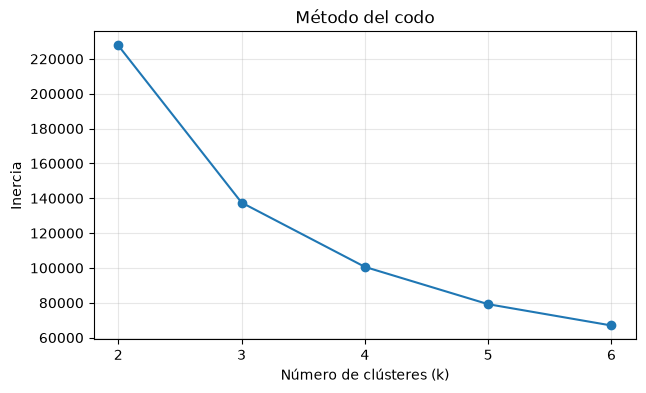

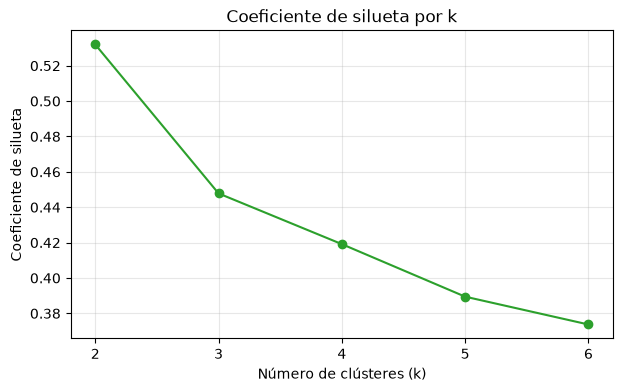

In [14]:
valores_k = [2, 3, 4, 5, 6]
inercias, siluetas = [], []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas,
                                     sample_size=5000, random_state=42))

tabla_k = pd.DataFrame({"k": valores_k, "Inercia": inercias, "Silueta": siluetas})
display(tabla_k.round(4))

# Método del codo
plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

# Coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(valores_k, siluetas, marker="o", color="tab:green")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(valores_k)
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

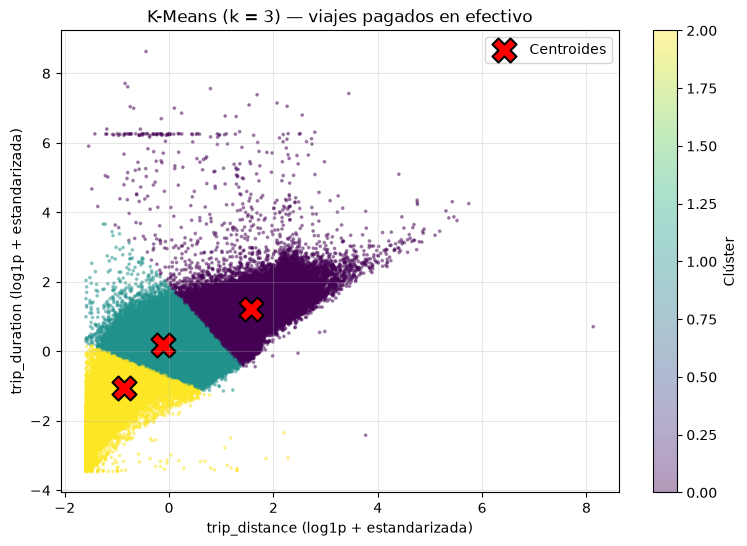

In [17]:
k_final = 3
modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas_final = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(9, 6))
dispersion = plt.scatter(X_escalado["trip_distance"], X_escalado["trip_duration"],
                         c=etiquetas_final, cmap="viridis", s=3, alpha=0.4)
plt.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=300,
            c="red", edgecolors="black", linewidths=1.5, label="Centroides")
plt.colorbar(dispersion, label="Clúster")
plt.title(f"K-Means (k = {k_final}) — viajes pagados en efectivo")
plt.xlabel("trip_distance (log1p + estandarizada)")
plt.ylabel("trip_duration (log1p + estandarizada)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [16]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas_final

tabla_clusters = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "count"),
    distancia_media_mi=("trip_distance", "mean"),
    distancia_mediana_mi=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median"),
).round(2)

display(tabla_clusters)

,cantidad_viajes,distancia_media_mi,distancia_mediana_mi,duracion_media_min,duracion_mediana_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**
Elegí k = 3 ya que en la gráfica del codo la caída más fuerte de la inercia ocurre al pasar de k = 2 a k = 3. A partir de ahí las reducciones son cada vez menores, por lo que el "codo" está en k = 3. La silueta más alta es la de k = 2 (0.532), pero con k = 3 sigue siendo aceptable (0.448) y es claramente mejor que con k = 4, 5 o 6 (0.419, 0.389 y 0.374). Además, dos grupos solo separarían viajes "cortos" y "largos", mientras que tres grupos dan una segmentación más útil e interpretable (cortos, medianos y largos), con centroides bien separados a lo largo de la diagonal en la gráfica de dispersión. Por eso k = 3 es el mejor equilibrio entre compacidad (inercia), separación (silueta) e interpretación.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
- **Clúster 2 — "Viajes cortos / trayectos de barrio":** 94,169 viajes. Distancia media de 0.80 mi (mediana de 0.76 mi) y duración media de 5.72 min (mediana de 5.82 min). Son recorridos muy breves dentro de la misma zona; la media y la mediana casi coinciden, así que el grupo es bastante homogéneo.
- **Clúster 1 — "Viajes urbanos medianos":** 125,521 viajes. Distancia media de 2.30 mi (mediana de 1.94 mi) y duración media de 15.43 min (mediana de 14.00 min). Es el traslado típico dentro de la ciudad, entre barrios cercanos.
- **Clúster 0 — "Viajes largos / interdistritales o al aeropuerto":** 62,395 viajes. Distancia media de 11.55 mi (mediana de 9.81 mi) y duración media de 39.48 min (mediana de 31.40 min). Son los recorridos más largos. Como la media es bastante mayor que la mediana, hay valores extremos (viajes muy largos o muy lentos) que sesgan el grupo hacia arriba.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**
El **clúster 0** tiene la mayor duración promedio (39.48 min, mediana de 31.40 min) y **también** la mayor distancia promedio (11.55 mi, mediana de 9.81 mi). Su duración es unas 2.6 veces la del clúster 1 (15.43 min) y su distancia unas 5 veces mayor (2.30 mi). Esto muestra que, en los pagos en efectivo, la distancia y la duración crecen juntas: los viajes más largos en millas también son los que más tiempo toman. Aun así, la duración crece menos que la distancia, porque los viajes largos suelen ir por vías rápidas y avanzan más millas por minuto.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**
El grupo más numeroso es el clúster 1 ("Viajes urbanos medianos"), con 125,521 viajes. En él predominan distancias cortas a moderadas, alrededor de 2 millas (media de 2.30 mi y mediana de 1.94 mi), y duraciones de unos 14–15 minutos (media de 15.43 min y mediana de 14.00 min). Es decir, la mayoría de los clientes que pagan en efectivo hacen traslados urbanos de distancia media y no viajes muy cortos ni muy largos.


---
### Lista de verificación antes de entregar

- [ x ] Se muestran la carga, exploración, limpieza y filtrado.
- [ x ] Se utilizaron las **dos variables indicadas**.
- [ x ] Se aplicaron `log1p` y `StandardScaler`.
- [ x ] Se calcularon inercia y silueta para `k = 2...6`.
- [ x ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ x ] Se visualizan los clústeres y sus centroides.
- [ x ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ x ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**